# Can a biochemical network remember an input?

This lab reproduces selected experiments from [Biswas, Clawson and Levin (2023)](https://doi.org/10.3390/ijms24010285), using their original BioModels in SBML. We ask whether a network's response depends on its stimulation history while keeping its reaction equations fixed.

We will observe retained responses, train and test a neutral cue, expose a misleading memory classification with a sham control, and test repeated interventions. RoadRunner runs the experiments; COPASI supplies an independent numerical check. See [the guide](../README.md) for provenance and differences from the MATLAB scripts. These are selected demonstrations, not a reproduction of all 35 networks.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "grn_memory").is_dir())
sys.path.insert(0, str(ROOT))
from grn_memory.experiments import retention_experiment, association_experiment, repeated_experiment, breaking_experiment
from grn_memory.analysis import regulation
from grn_memory.plotting import plot_case
from grn_memory.suite import compare

OUTPUT = ROOT / "results" / "notebook"
OUTPUT.mkdir(parents=True, exist_ok=True)
model = lambda number: ROOT / "models" / f"BIOMD{number:010d}.xml"
def show(name, kind, traces, score):
    plot_case(name, kind, traces, score, OUTPUT)
    display(Image(filename=str(OUTPUT / f"{name}.png")))

## 1. Memory as a measurable change

The dynamics have the reaction-network form $\dot{x}=V^{-1}Nv(x;\theta)$. In a three-species MAPK model, phosphorylation moves material between $M$, $M_p$, and $M_{pp}$. Training resets one selected concentration every 0.1 time unit; between resets, the original equations apply.

Let $B$ be the baseline mean response, $S$ its stimulated mean and $L$ its mean after withdrawing the input. The paper's retention measure is $\rho=(L-B)/(S-B)$, with memory called when $\rho\ge 0.5$ after a valid response. This tests a finite time window. It does not by itself establish an attractor or permanent memory.

,stimulus,response,baseline_mean,training_mean,relaxation_mean,retained_fraction,ucs_memory
0,Mpp,Mp,11.969343,134.440031,233.762567,1.810990,True
1,Mp,Mpp,1.479645,0.244125,1.265790,0.173089,False


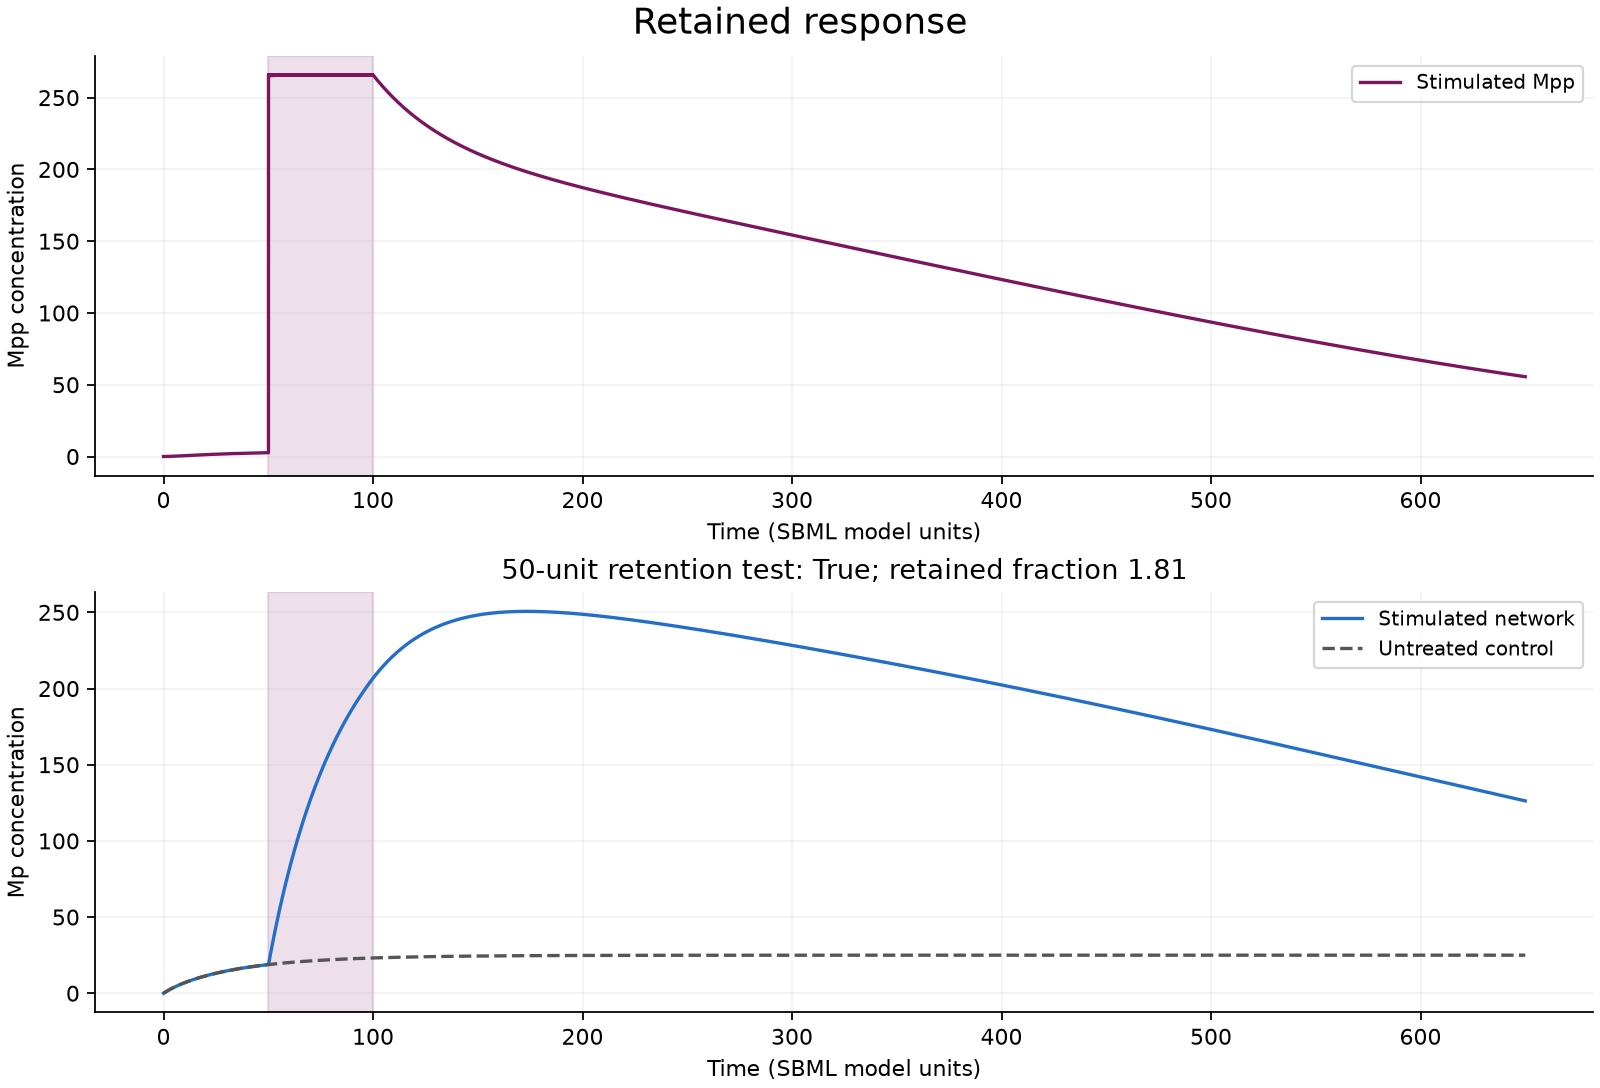

In [2]:
positive, positive_score = retention_experiment(model(31), "Mpp", "Mp", 1)
negative, negative_score = retention_experiment(model(31), "Mp", "Mpp", -1)
display(pd.DataFrame([positive_score, negative_score])[["stimulus", "response", "baseline_mean", "training_mean", "relaxation_mean", "retained_fraction", "ucs_memory"]])
show("retained_response", "retention", positive, positive_score)

The positive example continues to change after withdrawal, so $\rho$ can exceed one. The negative example retains less than half the induced shift. Both continue for another 500 time units, allowing a longer-term comparison.

**Check the conservation law.** With no external input, $M+M_p+M_{pp}$ is constant. Resetting $M_{pp}$ injects or removes material, so the total after training may be different. This is a physical state change, but it cannot alone demonstrate switching between attractors with the same conserved total.

In [3]:
species = ["M", "Mp", "Mpp"]
rows = []
for label, frame in [("baseline start", positive["baseline"].iloc[0]),
                     ("baseline end", positive["baseline"].iloc[-1]),
                     ("training end", positive["trained"].query("phase == 'train'").iloc[-1]),
                     ("long relaxation end", positive["trained"].iloc[-1])]:
    rows.append({"point": label, "total MAPK": float(frame[species].sum())})
display(pd.DataFrame(rows))

,point,total MAPK
0,baseline start,500.000000
1,baseline end,500.000000
2,training end,938.625939
3,long relaxation end,938.625939


## 2. Train a neutral cue, then test it

For network 15 (BioModel 26), the saved MATLAB row `[4,11,1,7,2,1,2]` maps to UCS `M_MKP3` up, response `Mp_MAPKK` down, and candidate CS `M` down. The species indices are one-based. We use SBML IDs to remove ambiguity in the figure's labels.

First UCS must change the response while CS alone must fail the twofold pretest. We then compare paired training with UCS-only training and test the CS after a wash interval. The original associative code uses a 1.5-fold threshold for this later stage. A sham probe continues the same trained state without CS.

pretest_passed                     True
ucs_memory                         True
pairing_memory                     True
transfer_memory                   False
associative_memory                 True
long_recall                        True
short_recall                      False
consolidation_candidate           False
probe_differs_from_paired_sham     True
dtype: bool

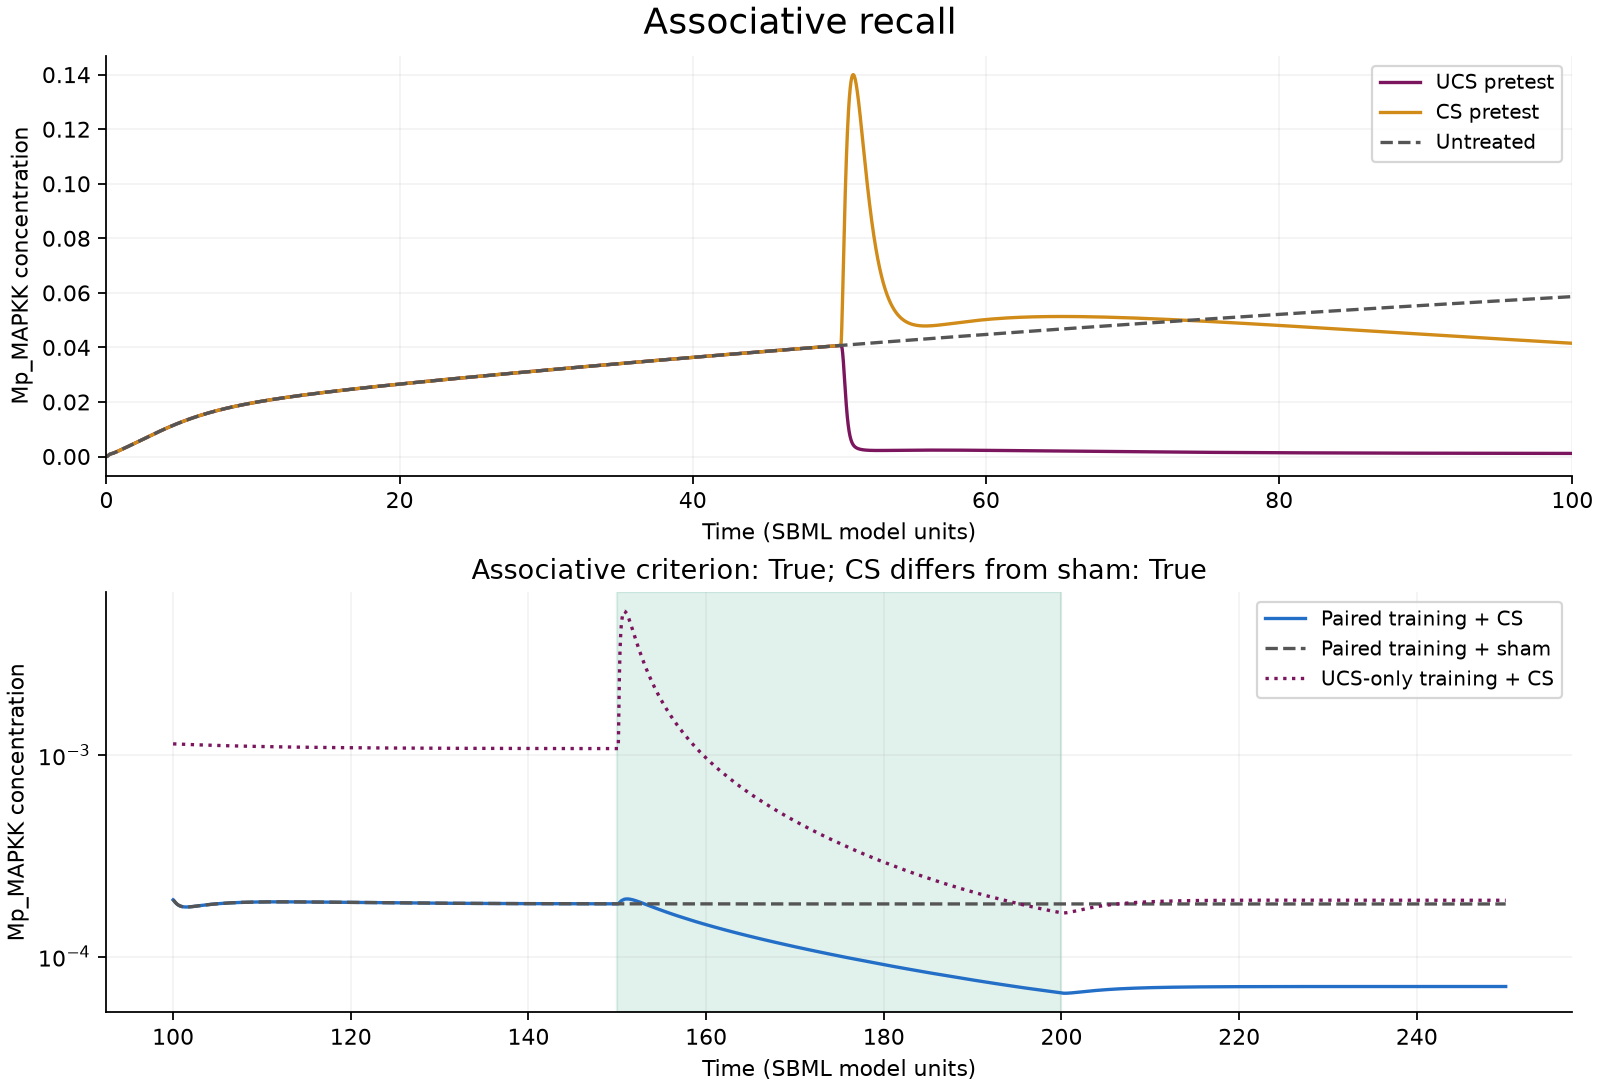

In [4]:
association, association_score = association_experiment(model(26), "M_MKP3", 1, "M", -1, "Mp_MAPKK")
display(pd.Series({k: v for k, v in association_score.items() if isinstance(v, bool)}))
show("associative_recall", "association", association, association_score)

The paired-trained probe differs from its sham and remains shifted during the next relaxation. The UCS-only condition also has some response to CS, but it narrowly misses the original threshold. Explore that dependence explicitly instead of treating the label as a sharp biological boundary.

In [5]:
R = association_score["response"]
def response_window(name, phase):
    return association[name].loc[association[name].phase == phase, R]
threshold_rows = []
for fold in [1.3, 1.4, 1.5, 1.6, 1.7, 2.0]:
    threshold_rows.append({"fold": fold, **{
        name: regulation(response_window(name, "wash"), response_window(name, "probe"), response_window("control", "probe"), fold) != 0
        for name in ["ucs", "paired"]}})
display(pd.DataFrame(threshold_rows).rename(columns={"ucs": "UCS-only recall", "paired": "Paired recall"}))

,fold,UCS-only recall,Paired recall
0,1.3,True,True
1,1.4,True,True
2,1.5,False,True
3,1.6,False,True
4,1.7,False,False
5,2.0,False,False


## 3. A positive label that does not require the cue

Another saved associative row is `[4,11,2,3,1,9,2]`. Here the response continues drifting after training. Compare the actual cue with the sham at the same time, rather than comparing only against the earlier wash window.

paper-style association         True
cue differs from sham          False
probe mean                 63.197487
sham mean                  63.197501
dtype: object

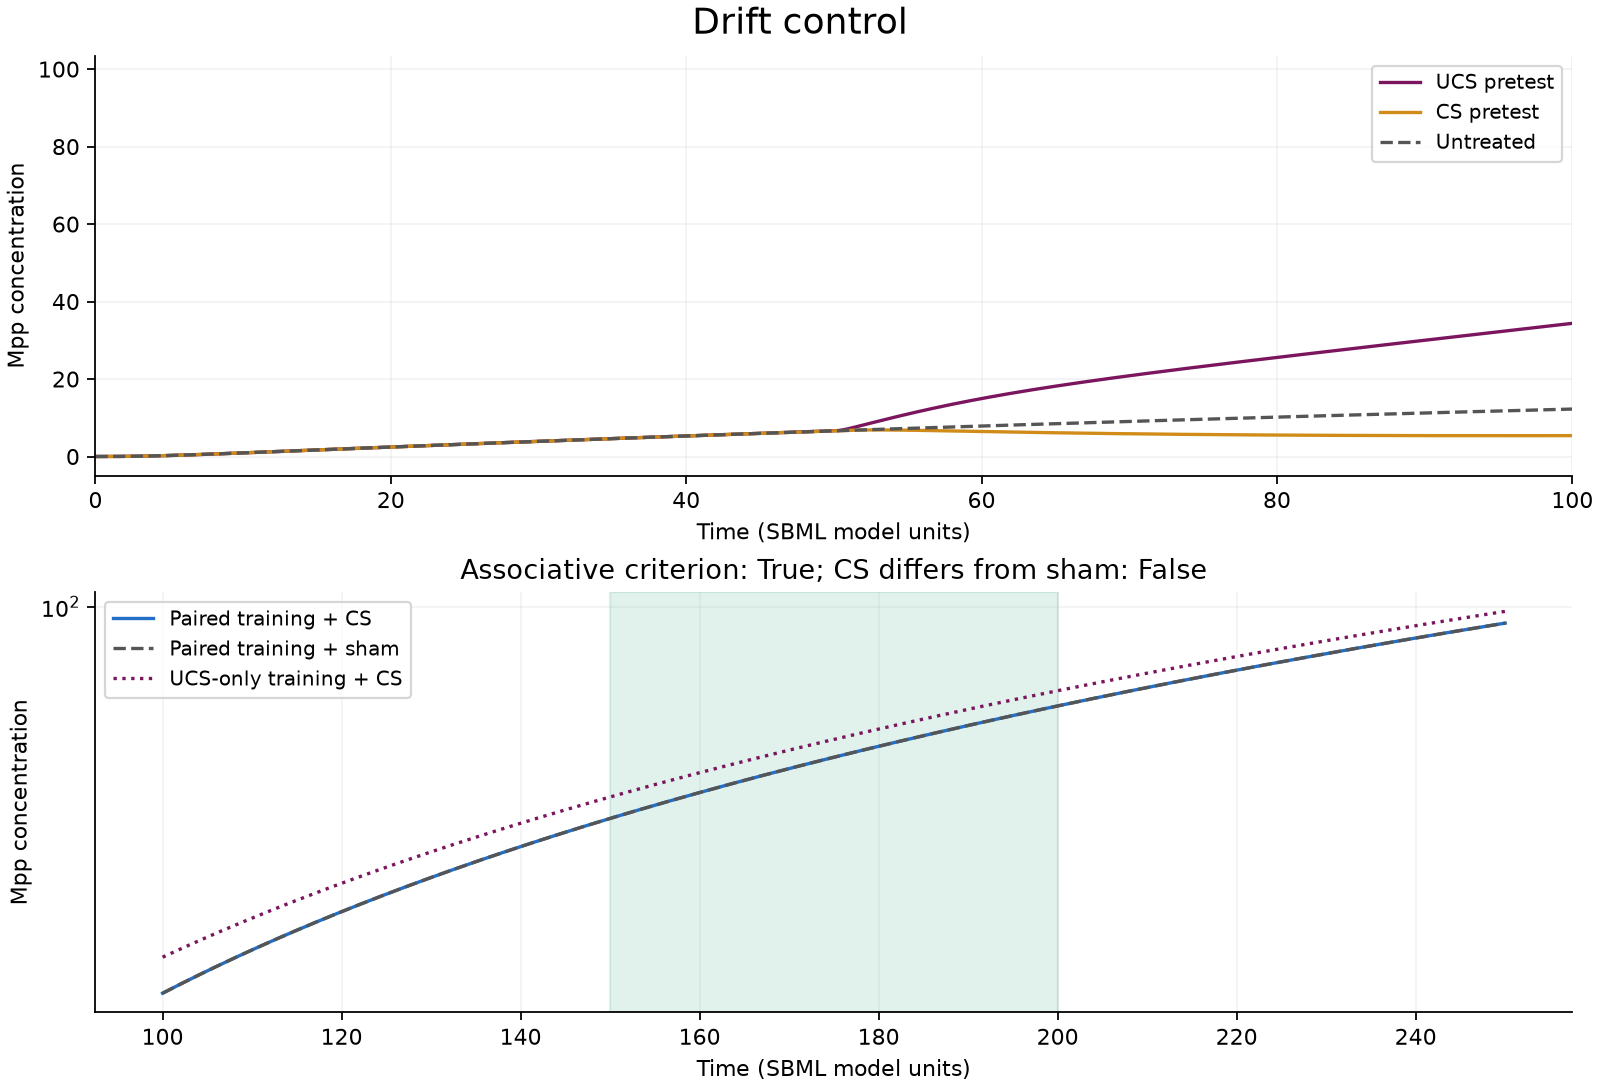

In [6]:
drift, drift_score = association_experiment(model(26), "M_MKP3", -1, "Mp_MKP3_dep", -1, "Mpp")
display(pd.Series({"paper-style association": drift_score["associative_memory"],
                   "cue differs from sham": drift_score["probe_differs_from_paired_sham"],
                   "probe mean": drift_score["means"]["paired"]["probe"],
                   "sham mean": drift_score["means"]["paired_sham"]["probe"]}))
show("drift_control", "association", drift, drift_score)

## 4. Repeated stimulation

The drug experiment repeats six inputs, increasing their duration from 50 to 100 time units and increasing the rest periods too. Model 10 reproduces a declining response; model 27 reproduces a growing response. The tables include the preceding local baseline and an untreated control.

Increasing pulse duration changes exposure. The concentration resets also change molecular totals. These examples reproduce the paper's response shapes, but fixed-dose sensitivity would require an additional experiment with matched pulse lengths and an appropriate normalization.

,pulse,duration,pre_mean,on_mean,increment,untreated_mean,direction
0,1,50,10.633333,23.836838,13.203505,34.502099,0
1,2,60,24.145230,21.726281,-2.418949,152.619789,0
2,3,70,17.968147,15.429158,-2.538989,249.796848,0
3,4,80,12.046930,9.931583,-2.115347,260.948113,0
4,5,90,7.347481,5.833667,-1.513814,212.397165,0
5,6,100,4.160884,3.262198,-0.898686,110.300816,0


,pulse,duration,pre_mean,on_mean,increment,untreated_mean,direction
0,1,50,5.139168,3257.011705,3251.872537,14.883969,1
1,2,60,7348.989193,11115.006295,3766.017102,28.494687,1
2,3,70,15690.656930,20071.686996,4381.030067,36.994051,0
3,4,80,25341.959714,30519.327988,5177.368273,42.289732,0
4,5,90,36660.021477,42857.355923,6197.334446,45.503281,0
5,6,100,50093.678404,57622.353261,7528.674858,47.374265,0


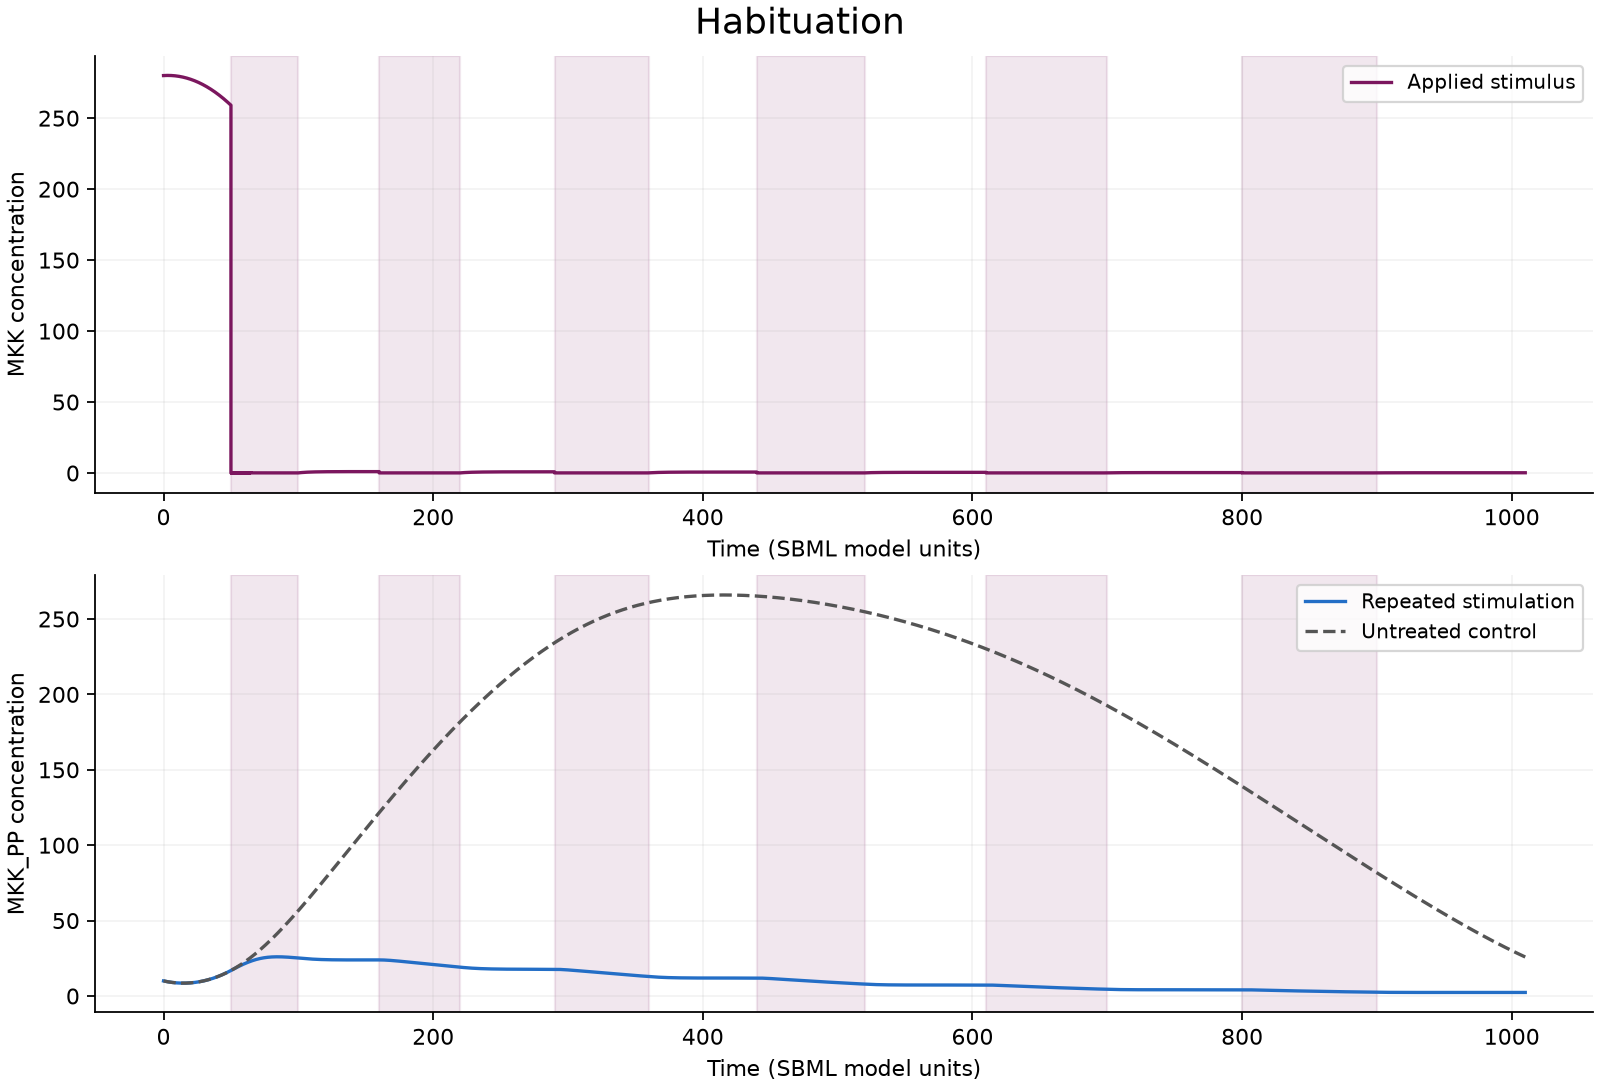

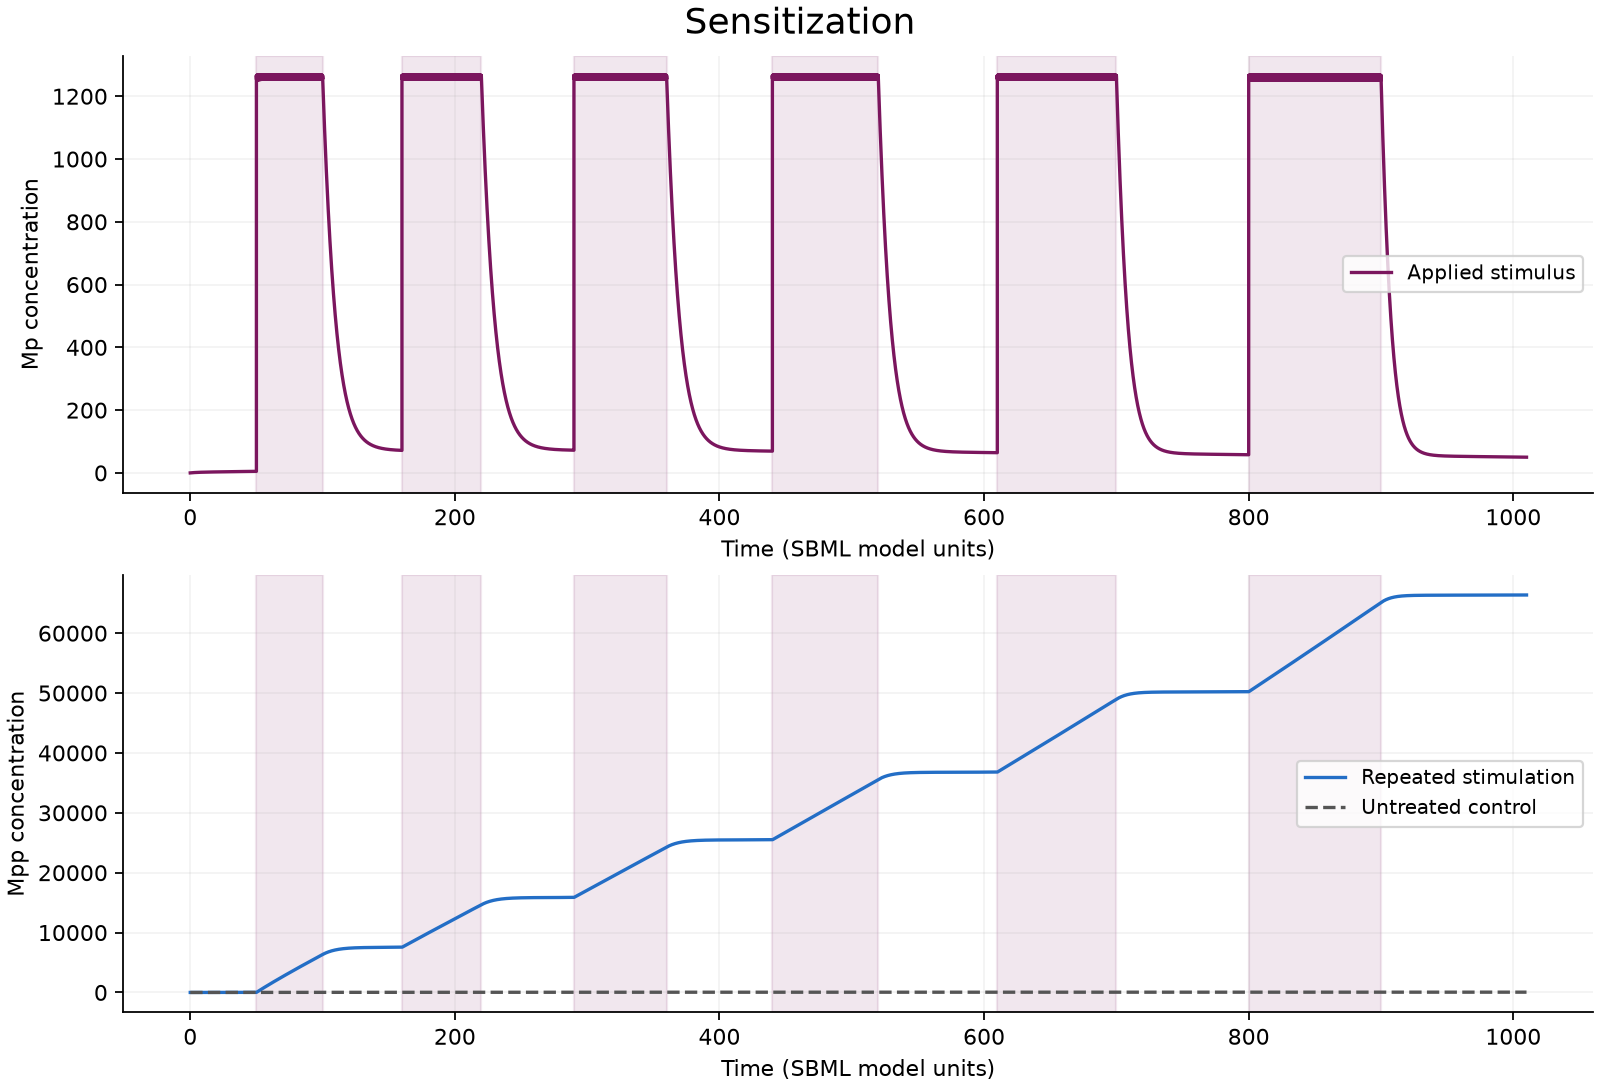

In [7]:
habit, habit_score = repeated_experiment(model(10), "MKK", "MKK_PP", -1)
sensit, sensit_score = repeated_experiment(model(27), "Mp", "Mpp", 1)
display(pd.DataFrame(habit_score["pulses"]))
display(pd.DataFrame(sensit_score["pulses"]))
show("habituation", "repeated", habit, habit_score)
show("sensitization", "repeated", sensit, sensit_score)

## 5. Can a second intervention reverse the response?

In model 29, repeated down-regulation of `MpT` changes the response of `Mpp`. From the same final state, compare an up-regulation of `M` with a sham intervention, then administer the original stimulus again. This controlled protocol tests the effect intended by the paper's habituation-breaking experiment. Its time windows are explicitly specified rather than fitted to the published plot.

,pre,rechallenge,increment
breaking,3.412613,5.387737,1.975124
sham_breaking,1.666107,0.185149,-1.480958


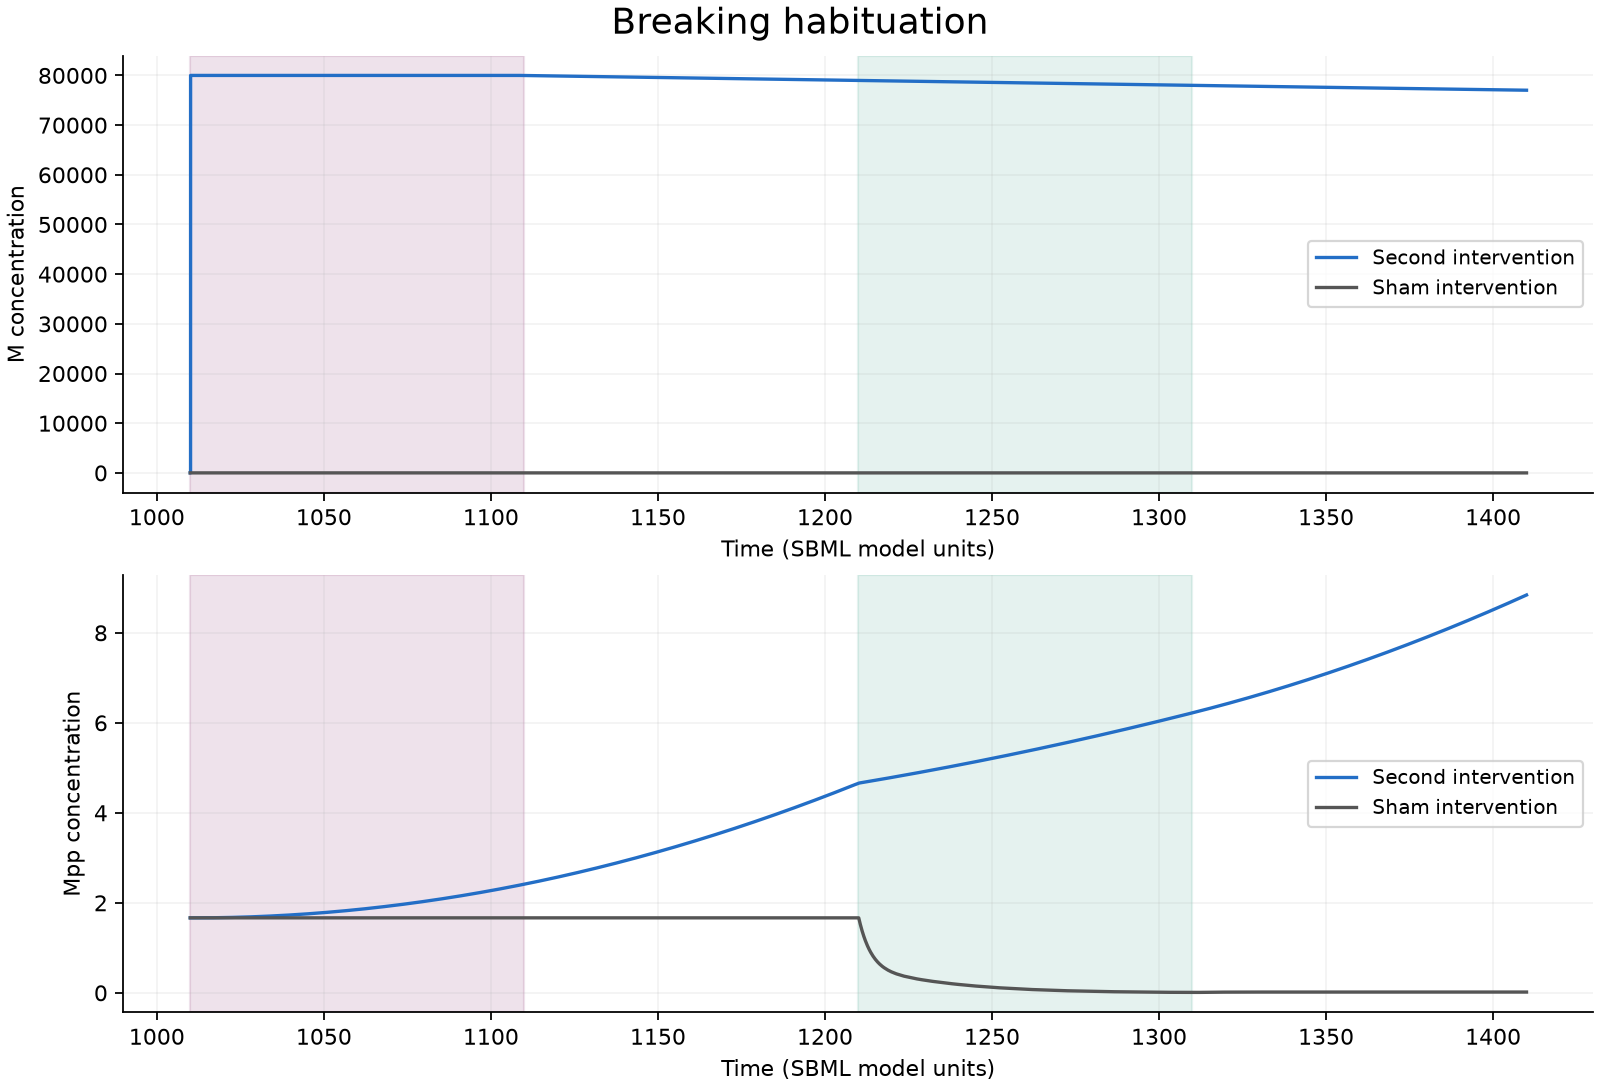

In [8]:
breaking, breaking_score = breaking_experiment(model(29), "MpT", "Mpp", -1, "M", 1)
display(pd.DataFrame(breaking_score["means"]).T)
show("breaking_habituation", "breaking", breaking, breaking_score)

## 6. Check the independent simulator

Run the retained-response protocol in COPASI with its own baseline calibration and compare all species at every output time. A tolerance-normalized maximum below one passes. The full command-line suite performs this check for all eight examples (44 trajectory pairs), and checks Boolean labels too. Agreement between solvers checks numerics, not the scientific interpretation.

In [9]:
oracle, oracle_score = retention_experiment(model(31), "Mpp", "Mp", 1, engine="copasi")
checks = {key: compare(positive[key], oracle[key]) for key in positive}
display(pd.DataFrame(checks).T)
assert all(item["passed"] for item in checks.values())
assert oracle_score["ucs_memory"] == positive_score["ucs_memory"]

,max_absolute_error,max_scaled_error,passed
baseline,0.0,0.000615,True
trained,0.000048,0.022123,True
control,0.0,0.000353,True


## Next experiments

1. Keep pulse lengths fixed and separate accumulation from sensitivity.
2. Vary the wash interval and ask whether the memory label changes.
3. Compare concentration resets with interventions that preserve a chosen molecular total.
4. Add unpaired training with matched exposure and timing controls.
5. Identify reproducible equilibria and transitions before constructing an RNM-style state graph.
6. Port these explicit protocols to a JAX backend, validate against both simulators, then check intervention gradients with finite differences.

The original MATLAB failure sentinel (`9999`) is not carried into the classifier. Missing model-specific MATLAB files, inconsistent baseline indexing and incomplete consolidation rechallenge also prevent claiming an exact rerun of the complete historical survey. The code and controls make those limits inspectable.